<a href="https://colab.research.google.com/github/arpanghosal/Geo_Sat_AI/blob/main/Sat_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q tensorflow-datasets

In [2]:
import tensorflow_datasets as tfds
print(tfds.__version__, hasattr(tfds, "load"))

4.9.10 True


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__, "| tfds:", tfds.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | tfds: 4.9.10
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
%pip install -q datasets
from datasets import load_dataset

In [6]:
ds = load_dataset("timm/eurosat-rgb")
class_names = ds["train"].features["label"].names
print(class_names)

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 55.3MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.4MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16200 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5400 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5400 [00:00<?, ? examples/s]

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [7]:
def to_tf(split):
    x = np.stack([np.array(im.convert("RGB").resize((64, 64)))
                  for im in ds[split]["image"]]).astype("uint8")
    y = np.array(ds[split]["label"], dtype="int64")
    return tf.data.Dataset.from_tensor_slices((x, y))

train_ds, val_ds, test_ds = to_tf("train"), to_tf("validation"), to_tf("test")
print("Train/val/test sizes:", len(train_ds), len(val_ds), len(test_ds))

Train/val/test sizes: 16200 5400 5400


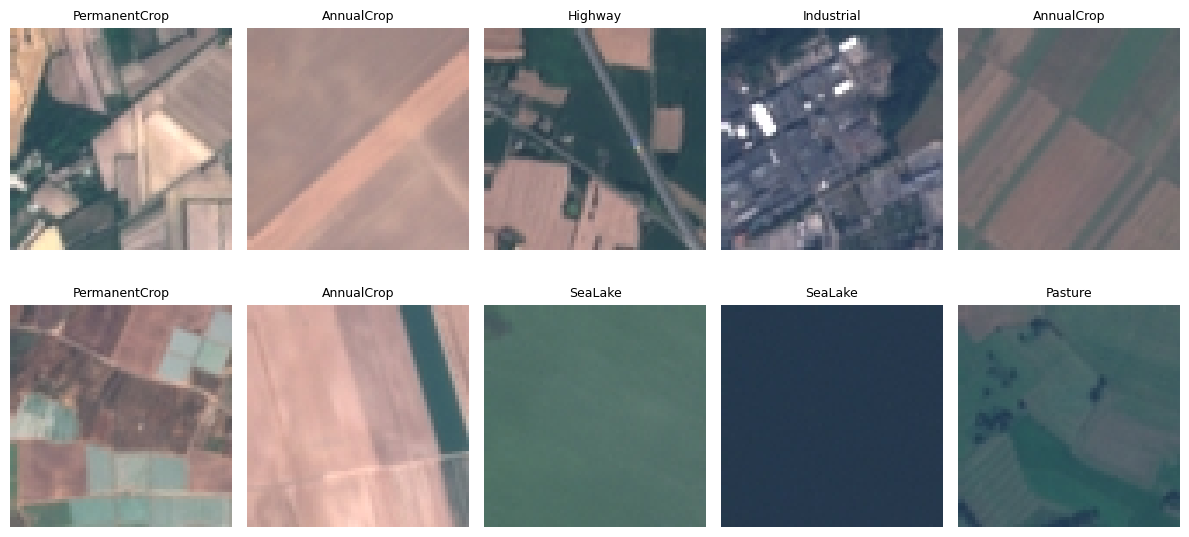

In [8]:
plt.figure(figsize=(12, 6))
for i, (img, label) in enumerate(train_ds.take(10)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(img.numpy())
    plt.title(class_names[label.numpy()], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [9]:
BATCH = 64
AUTOTUNE = tf.data.AUTOTUNE

def prep(img, label):
    return tf.cast(img, tf.float32) / 255.0, label

train = train_ds.map(prep, AUTOTUNE).shuffle(2000).batch(BATCH).prefetch(AUTOTUNE)
val   = val_ds.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
test  = test_ds.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

In [44]:
def conv_block(filters):
    return [
        layers.Conv2D(filters, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
    ]

model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.RandomFlip("horizontal_and_vertical"),   # augmentation, training only
    layers.RandomRotation(0.2),

    *conv_block(32),
    *conv_block(64),
    *conv_block(128),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(140, activation="relu"),
    layers.Dense(len(class_names), activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_11 (RandomFlip)     │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_11              │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_11     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 140)            │        18,060 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │         1,410 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,614 (443.80 KB)

 Trainable params: 113,166 (442.05 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/70
254/254 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.6420 - loss: 1.0043 - val_accuracy: 0.0841 - val_loss: 3.8342
Epoch 2/70
254/254 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.7456 - loss: 0.7049 - val_accuracy: 0.5522 - val_loss: 1.3161
Epoch 3/70
254/254 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7745 - loss: 0.6296 - val_accuracy: 0.7493 - val_loss: 0.7248
Epoch 4/70
254/254 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7885 - loss: 0.5877 - val_accuracy: 0.5607 - val_loss: 1.8977
Epoch 5/70
254/254 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8099 - loss: 0.5352 - val_accuracy: 0.7880 - val_loss: 0.6406
Epoch 6/70
254/254 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8288 - loss: 0.4869 - val_accuracy: 0.8378 - val_loss: 0.4808
Epoch 7/70
254/254 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8409 - loss: 0.4600 - val_accuracy: 0.8304 - val_loss: 0.4901
Epoch 8/70
254/254 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8541 - loss: 0.4191 - val_accu

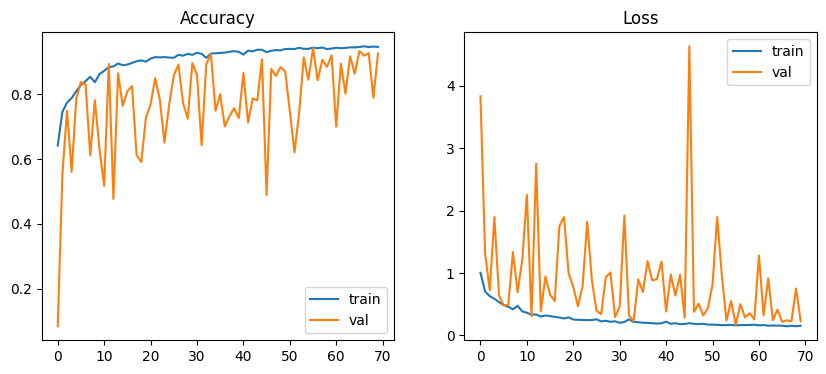

In [45]:
history = model.fit(train, validation_data=val, epochs=70)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss"); plt.legend()
plt.show()

85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9322 - loss: 0.2066
Test accuracy: 0.932

85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
                      precision    recall  f1-score   support

          AnnualCrop       0.98      0.92      0.95       596
              Forest       0.99      0.94      0.96       608
HerbaceousVegetation       0.82      0.89      0.85       573
             Highway       0.94      0.94      0.94       496
          Industrial       0.96      0.94      0.95       501
             Pasture       0.94      0.99      0.96       396
       PermanentCrop       0.94      0.80      0.86       538
         Residential       0.87      1.00      0.93       554
               River       0.94      0.94      0.94       529
             SeaLake       0.96      0.98      0.97       609

            accuracy                           0.93      5400
           macro avg       0.93      0.93      0.93      5400
        weighted avg       0.93      0.93      0.93      5

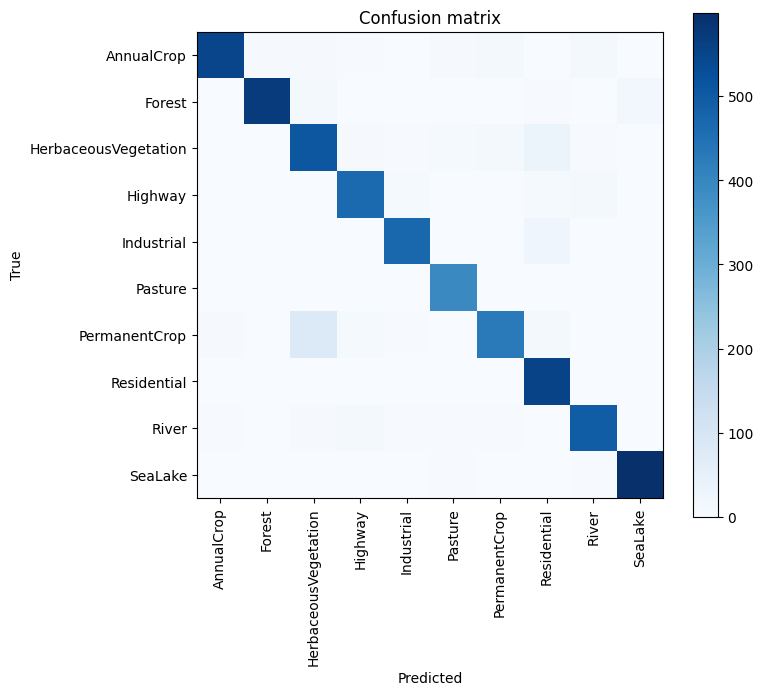

In [46]:
test_loss, test_acc = model.evaluate(test)
print(f"Test accuracy: {test_acc:.3f}\n")

y_true = np.concatenate([y.numpy() for _, y in test])
y_pred = np.argmax(model.predict(test), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(class_names)), class_names, rotation=90)
plt.yticks(range(len(class_names)), class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.colorbar()
plt.tight_layout()
plt.show()

Saving Screenshot 2026-10-23 at 12.46.07.png to Screenshot 2026-10-23 at 12.46.07 (2).png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


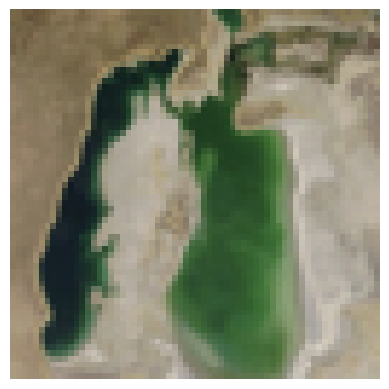

River                  56.3%
Highway                43.5%
Industrial             0.1%


In [51]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array

def classify(path, size=64):
    #img = load_img(path, target_size=(64, 64))
    img = Image.open(path).convert("RGB")
    #x = img_to_array(img)[None] / 255.0
    w, h = img.size
    s = min(w, h)
    img = img.crop(((w-s)//2, (h-s)//2, (w+s)//2, (h+s)//2))
    img = img.resize((size, size))
    x = np.array(img, dtype="float32")[None] / 255.0
    p = model.predict(x)[0]
    plt.imshow(img); plt.axis("off"); plt.show()
    for i in np.argsort(p)[::-1][:3]:
        print(f"{class_names[i]:<22} {p[i]:.1%}")

uploaded = files.upload()          # pick an image from your computer
classify(next(iter(uploaded)))

Saving Screenshot 2026-10-23 at 13.32.17.png to Screenshot 2026-10-23 at 13.32.17.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


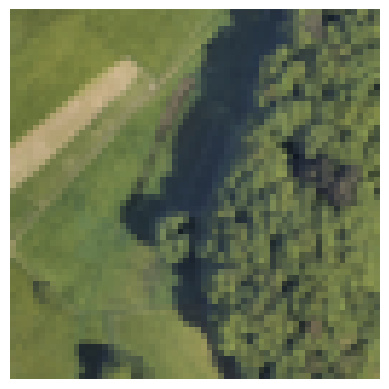

Highway                99.5%
River                  0.5%
AnnualCrop             0.0%


In [53]:
def classify(path, size=64):
    img = Image.open(path).convert("RGB")

    w, h = img.size
    s = min(w, h)
    img = img.crop(((w-s)//2, (h-s)//2, (w+s)//2, (h+s)//2))
    img = img.resize((size, size))
    x = np.array(img, dtype="float32")[None] / 255.0

    p = model.predict(x)[0]
    plt.imshow(img); plt.axis("off"); plt.show()
    for i in np.argsort(p)[::-1][:3]:
        print(f"{class_names[i]:<22} {p[i]:.1%}")

uploaded = files.upload()          # pick an image from your computer
classify(next(iter(uploaded)))

In [54]:
from PIL import Image
im = Image.open(next(iter(uploaded)))
print(im.size, im.mode)

(2010, 1170) RGBA


Saving Screenshot 2026-10-23 at 14.00.31.png to Screenshot 2026-10-23 at 14.00.31.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


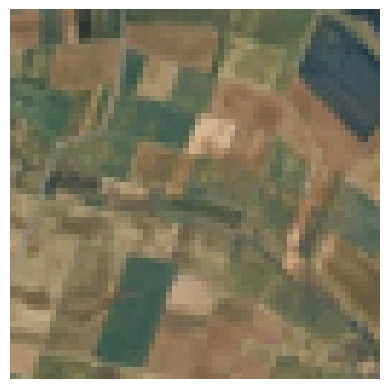

Highway                95.5%
PermanentCrop          2.9%
AnnualCrop             1.6%


In [56]:
def classify(path, size=64):
    img = Image.open(path).convert("RGB")

    w, h = img.size
    s = min(w, h)
    img = img.crop(((w-s)//2, (h-s)//2, (w+s)//2, (h+s)//2))
    img = img.resize((size, size))
    x = np.array(img, dtype="float32")[None] / 255.0

    p = model.predict(x)[0]
    plt.imshow(img); plt.axis("off"); plt.show()
    for i in np.argsort(p)[::-1][:3]:
        print(f"{class_names[i]:<22} {p[i]:.1%}")

uploaded = files.upload()          # pick an image from your computer
classify(next(iter(uploaded)))

In [60]:
BATCH = 64
AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE = 96

def prep(img, label):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

train = train_ds.map(prep, AUTOTUNE).shuffle(2000).batch(BATCH).prefetch(AUTOTUNE)
val   = val_ds.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
test  = test_ds.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

In [61]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3), include_top=False, weights="imagenet")
base.trainable = False  # unfreeze later for fine-tuning

model = models.Sequential([
    layers.Input(shape=(96, 96, 3)),
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.Rescaling(1./127.5, offset=-1),  # MobileNetV2's expected input range
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])

In [62]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_13 (RandomFlip)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_13              │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_13     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.7799 - loss: 0.6524 - val_accuracy: 0.8859 - val_loss: 0.3335
Epoch 2/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8711 - loss: 0.3804 - val_accuracy: 0.8972 - val_loss: 0.2955
Epoch 3/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8852 - loss: 0.3311 - val_accuracy: 0.9081 - val_loss: 0.2691
Epoch 4/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8940 - loss: 0.3074 - val_accuracy: 0.9091 - val_loss: 0.2631
Epoch 5/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8927 - loss: 0.2996 - val_accuracy: 0.9094 - val_loss: 0.2659
Epoch 6/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8956 - loss: 0.2998 - val_accuracy: 0.9176 - val_loss: 0.2365
Epoch 7/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8986 - loss: 0.2908 - val_accuracy: 0.9126 - val_loss: 0.2471
Epoch 8/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8994 - loss: 0.2838 - val_acc

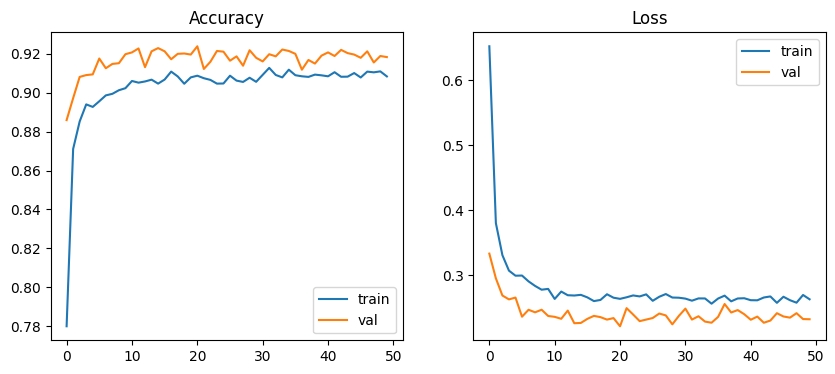

In [63]:
history = model.fit(train, validation_data=val, epochs=50)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss"); plt.legend()
plt.show()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_12 (RandomFlip)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_12              │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_12     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9243 - loss: 0.2238
Test accuracy: 0.924

85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step
                      precision    recall  f1-score   support

          AnnualCrop       0.92      0.94      0.93       596
              Forest       0.95      0.97      0.96       608
HerbaceousVegetation       0.86      0.95      0.90       573
             Highway       0.85      0.87      0.86       496
          Industrial       0.94      0.98      0.96       501
             Pasture       0.96      0.82      0.89       396
       PermanentCrop       0.93      0.86      0.89       538
         Residential       0.97      0.98      0.97       554
               River       0.88      0.88      0.88       529
             SeaLake       1.00      0.95      0.97       609

            accuracy                           0.92      5400
           macro avg       0.93      0.92      0.92      5400
        weighted avg       0.93      0.92      0.92     

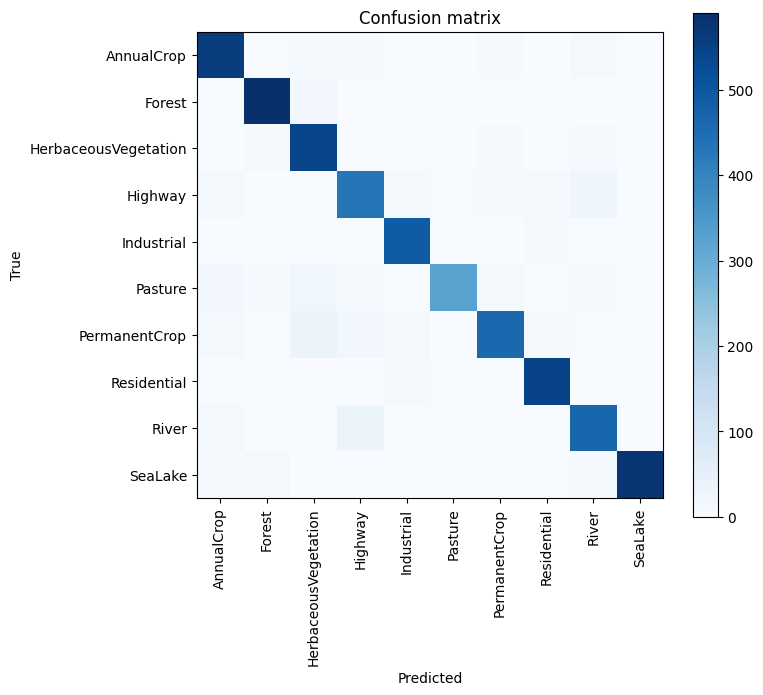

In [64]:
test_loss, test_acc = model.evaluate(test)
print(f"Test accuracy: {test_acc:.3f}\n")

y_true = np.concatenate([y.numpy() for _, y in test])
y_pred = np.argmax(model.predict(test), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(class_names)), class_names, rotation=90)
plt.yticks(range(len(class_names)), class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.colorbar()
plt.tight_layout()
plt.show()

Saving Screenshot 2026-10-23 at 14.00.31.png to Screenshot 2026-10-23 at 14.00.31 (2).png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


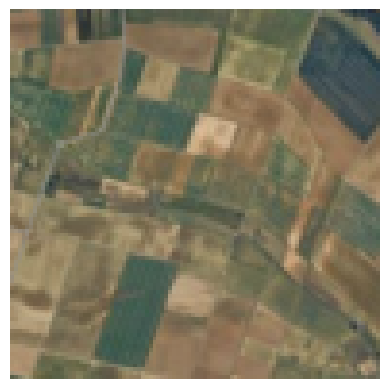

PermanentCrop          77.9%
Highway                20.9%
Industrial             1.2%


In [70]:
def classify(path, size=96):
    img = Image.open(path).convert("RGB")

    w, h = img.size
    s = min(w, h)
    img = img.crop(((w-s)//2, (h-s)//2, (w+s)//2, (h+s)//2))
    img = img.resize((size, size))
    x = np.array(img, dtype="float32")[None] #/ 255.0

    p = model.predict(x)[0]
    plt.imshow(img); plt.axis("off"); plt.show()
    for i in np.argsort(p)[::-1][:3]:
        print(f"{class_names[i]:<22} {p[i]:.1%}")

uploaded = files.upload()          # pick an image from your computer
classify(next(iter(uploaded)))

Saving Screenshot 2026-10-23 at 12.46.07.png to Screenshot 2026-10-23 at 12.46.07 (3).png
15.0 215.0 116.901184
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


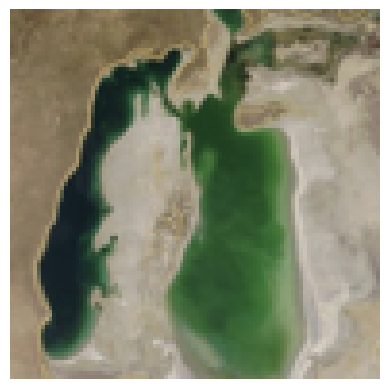

SeaLake                47.6%
Highway                43.5%
Industrial             6.8%


In [71]:
def classify(path, size=96):
    img = Image.open(path).convert("RGB")

    w, h = img.size
    s = min(w, h)
    img = img.crop(((w-s)//2, (h-s)//2, (w+s)//2, (h+s)//2))
    img = img.resize((size, size))
    x = np.array(img, dtype="float32")[None]
    print(x.min(), x.max(), x.mean())
    p = model.predict(x)[0]
    plt.imshow(img); plt.axis("off"); plt.show()
    for i in np.argsort(p)[::-1][:3]:
        print(f"{class_names[i]:<22} {p[i]:.1%}")

uploaded = files.upload()          # pick an image from your computer
classify(next(iter(uploaded)))